In [2]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Loading Data
df = pd.read_csv('/content/data_jobs.xlsx - Sheet1.csv')

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
## Skill count per month for data analysts
df_DA_India = df[(df['job_title'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()

df_DA_India['job_posted_month_no'] = df_DA_India['job_posted_date'].dt.month

# Explode job_skills column
df_DA_India_explode = df_DA_India.explode('job_skills')

In [7]:
# Group by month and job_skills
df_DA_India_pivot = df_DA_India_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

df_DA_India_pivot

job_skills,airflow,aws,bigquery,c,dax,excel,express,flow,github,go,...,outlook,power bi,powerpoint,python,r,slack,spark,spss,sql,tableau
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,1
3,0,0,1,1,0,1,1,0,1,0,...,0,0,1,1,1,1,1,0,2,0
4,0,0,0,0,0,1,0,0,0,1,...,1,0,1,1,0,1,0,0,1,1
5,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
6,0,1,0,0,0,1,1,1,0,0,...,0,0,1,3,1,0,1,0,2,0
7,1,0,0,0,0,2,0,0,0,1,...,0,1,1,1,2,0,0,1,1,2


In [9]:
# sorts by count
df_DA_India_pivot.loc['Total'] = df_DA_India_pivot.sum()
df_DA_India_pivot = df_DA_India_pivot[df_DA_India_pivot.loc['Total'].sort_values(ascending=False).index]
df_DA_India_pivot = df_DA_India_pivot.drop('Total')

df_DA_India_pivot

job_skills,sql,python,excel,tableau,powerpoint,r,spark,power bi,go,express,...,airflow,aws,dax,c,bigquery,github,outlook,jira,flow,spss
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,1,0,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
2,1,0,0,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2,1,1,0,1,1,1,0,0,1,...,0,0,0,1,1,1,0,0,0,0
4,1,1,1,1,1,0,0,0,1,0,...,0,0,0,0,0,0,1,1,0,0
5,0,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
6,2,3,1,0,1,1,1,0,0,1,...,0,1,0,0,0,0,0,0,1,0
7,1,1,2,2,1,2,0,1,1,0,...,1,0,0,0,0,0,0,0,0,1


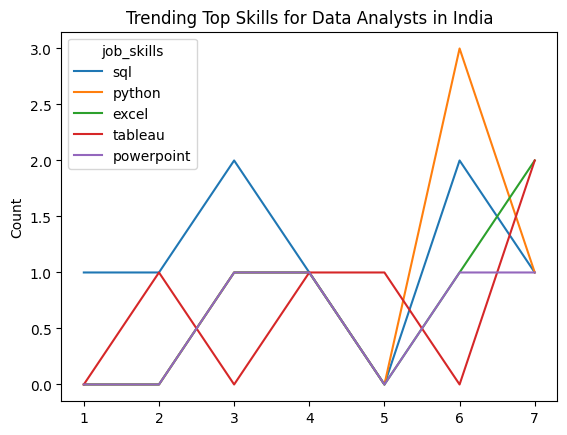

In [11]:
df_DA_India_pivot.iloc[:, :5].plot(kind='line')

plt.title('Trending Top Skills for Data Analysts in India')
plt.ylabel('Count')
plt.xlabel('')
plt.show()

In [13]:
# Get monthly totals
DA_totals = df_DA_India.groupby('job_posted_month_no').size()

DA_totals

,0
job_posted_month_no,
1,1
2,2
3,2
4,1
5,1
6,4
7,3
9,1


In [15]:
# divide first 12 rows of df_DA_India_pivot by DA_totals
df_DA_India_percent = df_DA_India_pivot.iloc[:12].div(DA_totals/100, axis=0)

# changes month number to month name
df_DA_India_percent = df_DA_India_percent.reset_index()
df_DA_India_percent['job_posted_month'] = df_DA_India_percent['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DA_India_percent = df_DA_India_percent.set_index('job_posted_month')
df_DA_India_percent = df_DA_India_percent.drop(columns='job_posted_month_no')

df_DA_India_percent

job_skills,sql,python,excel,tableau,powerpoint,r,spark,power bi,go,express,...,airflow,aws,dax,c,bigquery,github,outlook,jira,flow,spss
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,100.000000,0.000000,0.0,...,0.000000,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
Feb,50.000000,0.000000,0.000000,50.000000,0.000000,0.000000,50.0,0.000000,0.000000,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
Mar,100.000000,50.000000,50.000000,0.000000,50.000000,50.000000,50.0,0.000000,0.000000,50.0,...,0.000000,0.0,0.0,50.0,50.0,50.0,0.0,0.0,0.0,0.000000
Apr,100.000000,100.000000,100.000000,100.000000,100.000000,0.000000,0.0,0.000000,100.000000,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.000000
May,0.000000,0.000000,0.000000,100.000000,0.000000,0.000000,0.0,100.000000,0.000000,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
Jun,50.000000,75.000000,25.000000,0.000000,25.000000,25.000000,25.0,0.000000,0.000000,25.0,...,0.000000,25.0,0.0,0.0,0.0,0.0,0.0,0.0,25.0,0.000000
Jul,33.333333,33.333333,66.666667,66.666667,33.333333,66.666667,0.0,33.333333,33.333333,0.0,...,33.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.333333
Sep,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


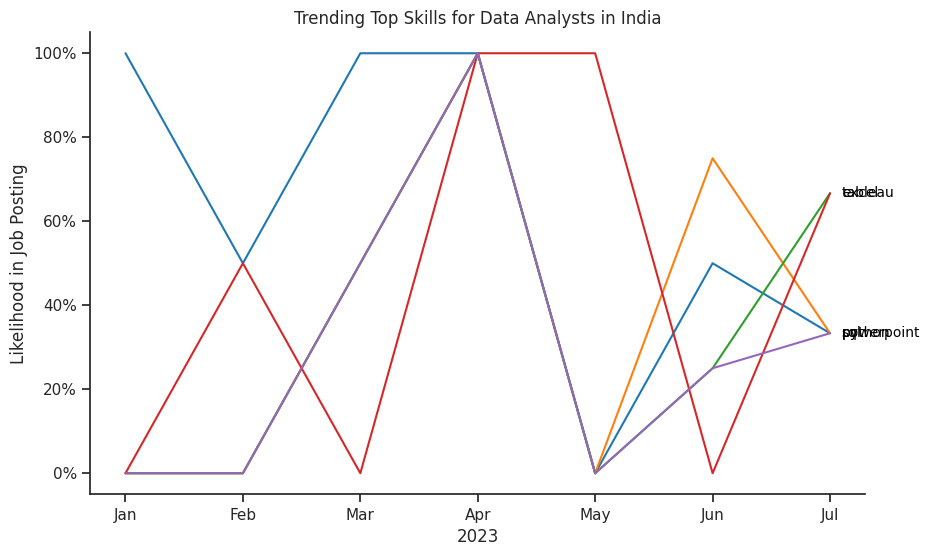

In [17]:
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt
import seaborn as sns

# Use India data
df_plot = df_DA_India_percent.iloc[:, :5]

# Set theme and plot
sns.set_theme(style='ticks')
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_plot, dashes=False, legend='full', palette='tab10')
sns.despine() # remove top and right spines

plt.title('Trending Top Skills for Data Analysts in India')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')
plt.legend().remove()
plt.gca().yaxis.set_major_formatter(PercentFormatter(decimals=0))

# Annotate the plot with the top 5 skills near the last valid points (July, which is index 6)
for i in range(5):
    # Using index 6 (July) to avoid the NaN values in September
    plt.text(6.1, df_plot.iloc[6, i], df_plot.columns[i], color='black', fontsize=10, va='center')

plt.show()